# Máquinas Térmicas – Lección 18
## Máquinas de Refrigeración

**Autor:** Camilo Bayona  
**Fecha:** 20/11/2025



## Objetivos de aprendizaje

Al finalizar esta lección, el/la estudiante será capaz de:

- Explicar el **principio termodinámico** de una máquina de refrigeración y su diferencia frente a un motor térmico.
- Describir la **química y termodinámica del cambio de fase** en ciclos por **compresión de vapor** y **absorción**.
- Interpretar y usar el **diagrama P–h** en el análisis de ciclos de refrigeración, y verificar por qué el área de un diagrama termodinámico representa trabajo **solo cuando el ciclo es reversible**.
- Identificar y modelar los **componentes principales**: compresor, condensador, válvula de expansión y evaporador.
- Definir y calcular el **Coeficiente de Rendimiento (COP)** para ciclos por compresión y por absorción, y comparar **las dos formas** de componer una máquina de refrigeración.
- Establecer balances de **masa y energía** en los componentes clave (compresor, condensador, evaporador, absorbedor, generador).
- Reconocer las principales **no idealidades** de los ciclos reales, incluida la irreversibilidad intrínseca de la válvula de expansión.
- Identificar la **instrumentación** necesaria para operar y validar un ciclo de refrigeración, y contrastarla con la del ciclo Rankine de potencia (Lección 13).
- Introducir el uso de la **psicrometría** para análisis de acondicionamiento de aire, con una carta psicrométrica real.

In [ ]:
# Instalación solo en Google Colab; en el entorno local del curso es un no-op
import sys
if "google.colab" in sys.modules:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "matplotlib", "ipywidgets", "numpy", "scipy", "CoolProp"], check=True)

In [ ]:
# === Setup =================================================================
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Circle, Rectangle
from ipywidgets import (interact, interactive_output, FloatSlider, IntSlider,
                        Dropdown, Checkbox, HBox, VBox)
from IPython.display import display
from CoolProp.CoolProp import PropsSI, HAPropsSI

# Paleta del proyecto (misma familia que Lecciones 7-17; roles nuevos de esta leccion)
COL = {"evaporador": "#2a78d6", "compresor": "#4a3aa7", "condensador": "#eb6834",
       "valvula": "#8a8a86", "absorbedor": "#8e44ad", "generador": "#c0392b",
       "bomba_sol": "#1b7a3d", "aire": "#1baf7a", "perdida": "#e34948", "tinta": "#3a3a38"}

def plot_dome_Ph(fluid, ax):
    # Domo de saturacion en el diagrama P-h (CoolProp), eje P logaritmico (convencion estandar)
    Tt = PropsSI("Ttriple", fluid) + 0.5
    Tc_ = PropsSI("Tcrit", fluid) - 0.2
    Ts = np.linspace(Tt, Tc_, 250)
    h_l = np.array([PropsSI("H", "T", T, "Q", 0, fluid) for T in Ts]) / 1e3
    h_v = np.array([PropsSI("H", "T", T, "Q", 1, fluid) for T in Ts]) / 1e3
    P = np.array([PropsSI("P", "T", T, "Q", 0, fluid) for T in Ts]) / 1e3
    ax.plot(h_l, P, color="#777777", lw=1.3)
    ax.plot(h_v, P, color="#777777", lw=1.3)
    ax.set_yscale("log")
    ax.set_xlabel("$h$ [kJ/kg]"); ax.set_ylabel("$P$ [kPa] (escala log)")

def area_ciclo(x_loop, y_loop):
    # Shoelace -- misma funcion validada en NB16 (area encerrada de un lazo cerrado)
    x, y = np.asarray(x_loop), np.asarray(y_loop)
    return 0.5*abs(np.sum(x[:-1]*y[1:] - x[1:]*y[:-1]) + (x[-1]*y[0] - x[0]*y[-1]))

def dibujar_ciclo_refrigeracion(modo="compresion", resaltar=None, figsize=(10.5, 3.2)):
    # Diagrama de bloques del ciclo (mismo patron de dibujar_planta_vapor de NB16)
    if modo == "compresion":
        ruta = [("evaporador", "Evaporador"), ("compresor", "Compresor"),
                ("condensador", "Condensador"), ("valvula", "Válvula de\nexpansión")]
    else:
        ruta = [("evaporador", "Evaporador"), ("absorbedor", "Absorbedor"),
                ("bomba_sol", "Bomba de\nsolución"), ("generador", "Generador"),
                ("condensador", "Condensador"), ("valvula", "Válvula de\nexpansión")]
    n = len(ruta)
    fig, ax = plt.subplots(figsize=figsize)
    xs = np.linspace(0.9, 0.9 + 1.55*(n-1), n)
    y = 1.0
    for x, (clave, nombre) in zip(xs, ruta):
        fc = COL[clave] if resaltar == clave else "#fdf6e3"
        ec = COL["tinta"] if resaltar != clave else COL[clave]
        lw = 1.1 if resaltar != clave else 2.4
        ax.add_patch(FancyBboxPatch((x-0.62, y-0.42), 1.24, 0.84, boxstyle="round,pad=0.05",
                                     fc=fc, ec=ec, lw=lw))
        ax.text(x, y, nombre, ha="center", va="center", fontsize=8.3,
                fontweight="bold" if resaltar == clave else "normal")
    for k in range(n-1):
        ax.add_patch(FancyArrowPatch((xs[k]+0.64, y), (xs[k+1]-0.64, y), arrowstyle="-|>",
                                      mutation_scale=12, color=COL["tinta"]))
    ax.add_patch(FancyArrowPatch((xs[-1], y-0.45), (xs[0], y-0.45), connectionstyle="arc3,rad=-0.3",
                                  arrowstyle="-|>", mutation_scale=12, color=COL["evaporador"], lw=1.3, ls="--"))
    # fuente fria / sumidero caliente
    ax.text(xs[0], y+0.75, "fuente fría\n(espacio a enfriar)", ha="center", fontsize=7.5, color=COL["evaporador"])
    ax.add_patch(FancyArrowPatch((xs[0], y+0.55), (xs[0], y+0.46), arrowstyle="-|>",
                                  mutation_scale=10, color=COL["evaporador"]))
    i_cond = [k for k,(c,_) in enumerate(ruta) if c == "condensador"][0]
    ax.text(xs[i_cond], y+0.75, "sumidero caliente\n(ambiente)", ha="center", fontsize=7.5, color=COL["condensador"])
    ax.add_patch(FancyArrowPatch((xs[i_cond], y+0.46), (xs[i_cond], y+0.55), arrowstyle="-|>",
                                  mutation_scale=10, color=COL["condensador"]))
    ax.set_xlim(xs[0]-0.9, xs[-1]+0.9); ax.set_ylim(-0.6, y+1.1); ax.axis("off")
    plt.tight_layout(); plt.show()

print("Setup OK")

Setup OK


## 1. Principio de funcionamiento de una máquina de refrigeración

Los ciclos de refrigeración son procesos termodinámicos que permiten la transferencia de calor desde una región de baja temperatura a una de alta temperatura. Estos ciclos son fundamentales en aplicaciones como aires acondicionados, refrigeradores y sistemas de refrigeración industrial. En esta lección, abordaremos los principios fundamentales de las máquinas de refrigeración.

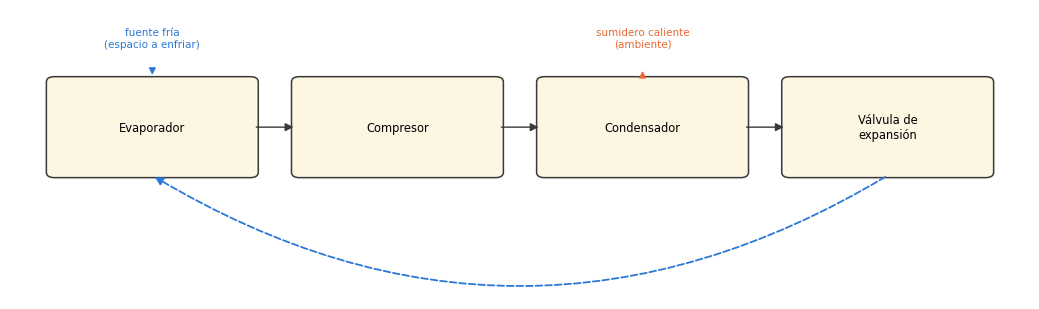

In [ ]:
dibujar_ciclo_refrigeracion("compresion")

## 2. Química y Termodinámica del Cambio de Fase en Ciclos de Refrigeración por Compresión

El cambio de fase es un fenómeno fundamental en los ciclos de refrigeración, y su comprensión es esencial para el diseño y operación eficiente de los sistemas de refrigeración. En los ciclos de refrigeración por compresión, el refrigerante experimenta cambios de fase repetidos entre líquido y vapor.

### 2.1. Química del Cambio de Fase

El cambio de fase implica una transición de una fase a otra, como de líquido a gas (ebullición) o de gas a líquido (condensación). A nivel molecular, esto se traduce en cambios en la energía cinética y potencial de las moléculas del refrigerante:

- **Ebullición:** Cuando un líquido se calienta, sus moléculas ganan energía cinética. Al alcanzar el punto de ebullición, la energía cinética es suficiente para superar las fuerzas intermoleculares que mantienen las moléculas juntas en la fase líquida, permitiendo que se evaporen y formen vapor.

- **Condensación:** Al enfriarse, las moléculas de vapor pierden energía cinética. Cuando la energía cinética es insuficiente para superar las fuerzas intermoleculares, las moléculas se agrupan y condensan, formando líquido.

Es importante destacar que el cambio de fase ocurre a una temperatura constante, conocida como temperatura de saturación, para una presión dada. Durante este proceso, el refrigerante absorbe o libera calor latente sin cambiar su temperatura.

### 2.2. Termodinámica del Cambio de Fase

Desde una perspectiva termodinámica, el cambio de fase implica cambios en varias propiedades termodinámicas, como la entalpía, la entropía y el volumen específico.

- **Entalpía (h):** La entalpía es una medida de la energía total de un sistema. Durante un cambio de fase, la entalpía del refrigerante cambia debido al calor latente asociado con la transición. Por ejemplo, durante la ebullición, el refrigerante absorbe calor latente de vaporización, lo que resulta en un aumento de su entalpía. Durante la condensación, el refrigerante libera calor latente de condensación, lo que disminuye su entalpía.

- **Entropía (s):** La entropía es una medida del desorden o aleatoriedad molecular de un sistema. Durante el cambio de fase, la entropía también experimenta cambios. En la ebullición, el paso de líquido a gas implica un aumento en el desorden molecular, lo que se traduce en un aumento de la entropía. Por otro lado, durante la condensación, el paso de gas a líquido implica una disminución en el desorden molecular, lo que resulta en una disminución de la entropía.

- **Volumen específico (v):** El volumen específico es el volumen por unidad de masa. Durante el cambio de fase, el volumen específico del refrigerante cambia significativamente. En la ebullición, el refrigerante pasa de un estado líquido denso a un estado gaseoso menos denso, lo que resulta en un aumento en el volumen específico. Durante la condensación, el proceso es inverso, y el volumen específico disminuye.

## 3. Diagrama Presión–Entalpía (P–h)

Para comprender a fondo la termodinámica del cambio de fase en los ciclos de refrigeración, es esencial considerar las propiedades termodinámicas en diferentes puntos del ciclo y cómo estas propiedades varían con las condiciones operativas.


El diagrama P-h es una herramienta esencial para visualizar y analizar los ciclos de refrigeración. En este diagrama, la entalpía se traza en el eje horizontal y la presión en el eje vertical. Las curvas de saturación líquida y saturación de vapor definen la región de mezcla bifásica.

Las principales características del diagrama P-h incluyen:

- **Línea de Saturación Líquida:** Representa las condiciones bajo las cuales el refrigerante está en equilibrio como líquido saturado. A la izquierda de esta línea, el refrigerante está en estado subenfriado.

- **Línea de Saturación de Vapor:** Representa las condiciones bajo las cuales el refrigerante está en equilibrio como vapor saturado. A la derecha de esta línea, el refrigerante está en estado sobrecalentado.

- **Región Bifásica:** El área entre las líneas de saturación líquida y de vapor. En esta región, el refrigerante existe en equilibrio como una mezcla de líquido y vapor.

El diagrama P-h también muestra las líneas de isoterma, que representan condiciones de temperatura constante. Estas líneas son útiles para analizar los cambios de fase y las propiedades termodinámicas en diferentes puntos del ciclo de refrigeración.

El widget siguiente reemplaza la figura genérica del "ciclo de Rankine inverso": resuelve el ciclo de compresión de vapor **real** (refrigerante seleccionable, vía CoolProp) sobre el diagrama P-h, y lo compara en un segundo panel T-s contra un **ciclo de referencia totalmente reversible** (con un expansor isentrópico hipotético en vez de la válvula real) — **solo en ese ciclo de referencia** el área T-s coincide exactamente con el trabajo neto (mismo hallazgo y misma verificación de NB16: $\oint T\,ds=w_{net}$ exige reversibilidad total). La válvula de expansión real introduce una irreversibilidad intrínseca —ni siquiera el ciclo "ideal" de refrigeración es totalmente reversible— que se cuantifica aquí como una penalización real de COP, no solo una afirmación cualitativa.

In [ ]:
# WIDGET 1 -- ciclo de compresion de vapor real (P-h) + ciclo de referencia reversible (T-s)
def ciclo_refrigeracion(T_evap_C=-10.0, T_cond_C=45.0, fluido="R134a"):
    Te, Tc = T_evap_C+273.15, T_cond_C+273.15
    Pe = PropsSI("P","T",Te,"Q",1,fluido); Pc = PropsSI("P","T",Tc,"Q",1,fluido)

    # --- Ciclo REAL (valvula de expansion isentalpica) ---
    h1 = PropsSI("H","P",Pe,"Q",1,fluido); s1 = PropsSI("S","P",Pe,"Q",1,fluido)
    h2 = PropsSI("H","P",Pc,"S",s1,fluido)
    h3 = PropsSI("H","P",Pc,"Q",0,fluido); s3 = PropsSI("S","P",Pc,"Q",0,fluido)
    h4 = h3
    w_comp = h2-h1; q_evap = h1-h4
    COP_real = q_evap/w_comp

    # --- Ciclo de REFERENCIA reversible (expansor isentropico hipotetico, NO una valvula real) ---
    h4s = PropsSI("H","P",Pe,"S",s3,fluido)
    w_exp = h3-h4s
    w_net_rev = w_comp - w_exp
    q_evap_rev = h1-h4s
    COP_rev = q_evap_rev/w_net_rev

    fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12.5, 5))
    # Panel P-h: ciclo real
    plot_dome_Ph(fluido, ax0)
    h_cycle = np.array([h1,h2,h3,h4,h1])/1e3
    P_cycle = np.array([Pe,Pc,Pc,Pe,Pe])/1e3
    ax0.plot(h_cycle, P_cycle, "-o", color=COL["compresor"], lw=2.2, ms=6)
    for k,(hx,Px) in enumerate(zip(h_cycle[:4],P_cycle[:4]), start=1):
        ax0.annotate(str(k), (hx,Px), textcoords="offset points", xytext=(6,6), fontsize=10, fontweight="bold")
    ax0.set_title(f"Ciclo REAL (P-h) — {fluido}\nCOP = {COP_real:.2f}")

    # Panel T-s: ciclo de referencia reversible, area sombreada = w_net_rev (verificado)
    n = 120
    P_12 = np.linspace(Pe,Pc,n); T_12 = np.array([PropsSI("T","P",p,"S",s1,fluido) for p in P_12]); s_12 = np.full(n,s1)
    h_23 = np.linspace(h2,h3,n)
    T_23 = np.array([PropsSI("T","P",Pc,"H",h,fluido) for h in h_23])
    s_23 = np.array([PropsSI("S","P",Pc,"H",h,fluido) for h in h_23])
    P_34 = np.linspace(Pc,Pe,n); T_34 = np.array([PropsSI("T","P",p,"S",s3,fluido) for p in P_34]); s_34 = np.full(n,s3)
    h_41 = np.linspace(h4s,h1,n)
    T_41 = np.array([PropsSI("T","P",Pe,"H",h,fluido) for h in h_41])
    s_41 = np.array([PropsSI("S","P",Pe,"H",h,fluido) for h in h_41])
    s_loop = np.concatenate([s_12,s_23,s_34,s_41])/1e3
    T_loop = np.concatenate([T_12,T_23,T_34,T_41])-273.15
    area = area_ciclo(s_loop, T_loop+273.15)

    ax1.fill(s_loop, T_loop, color=COL["evaporador"], alpha=0.16, zorder=1)
    ax1.plot(s_loop, T_loop, color=COL["evaporador"], lw=2.2, zorder=3)
    ax1.set_xlabel("$s$ [kJ/(kg·K)]"); ax1.set_ylabel("$T$ [°C]")
    ax1.set_title(f"Ciclo de REFERENCIA reversible (T-s)\n$w_{{net}}$={w_net_rev/1e3:.2f} kJ/kg = área "
                  f"({area:.2f} kJ/kg)   COP$_{{rev}}$={COP_rev:.2f}", fontsize=10)
    ax1.grid(alpha=0.2)
    plt.tight_layout(); plt.show()
    print(f"Penalización de COP por la irreversibilidad de la válvula real: "
          f"{100*(COP_rev-COP_real)/COP_rev:.1f} %  (COP_real={COP_real:.2f} vs. COP_rev={COP_rev:.2f})")

interact(ciclo_refrigeracion,
         T_evap_C=FloatSlider(-10.0, min=-30.0, max=10.0, step=1.0, description="T evap. [°C]"),
         T_cond_C=FloatSlider(45.0, min=25.0, max=60.0, step=1.0, description="T cond. [°C]"),
         fluido=Dropdown(options=["R134a", "R410A", "Ammonia", "R290"], value="R134a", description="refrigerante"));

interactive(children=(FloatSlider(value=-10.0, description='T evap. [°C]', max=10.0, min=-30.0, step=1.0), Flo…

## 4. Componentes básicos de un ciclo de refrigeración por compresión

Un ciclo de refrigeración típico consta de los siguientes componentes principales:

1. **Compresor:** Aumenta la presión y la temperatura del refrigerante.
2. **Condensador:** Libera calor del refrigerante, lo que provoca que se condense y cambie de fase de gas a líquido.
3. **Válvula de expansión:** Reduce la presión del refrigerante, lo que provoca una disminución en su temperatura.
4. **Evaporador:** Absorbe calor del entorno, lo que provoca que el refrigerante se evapore y cambie de fase de líquido a gas.

El refrigerante circula a través de estos componentes en un ciclo cerrado, experimentando cambios de fase y de temperatura.

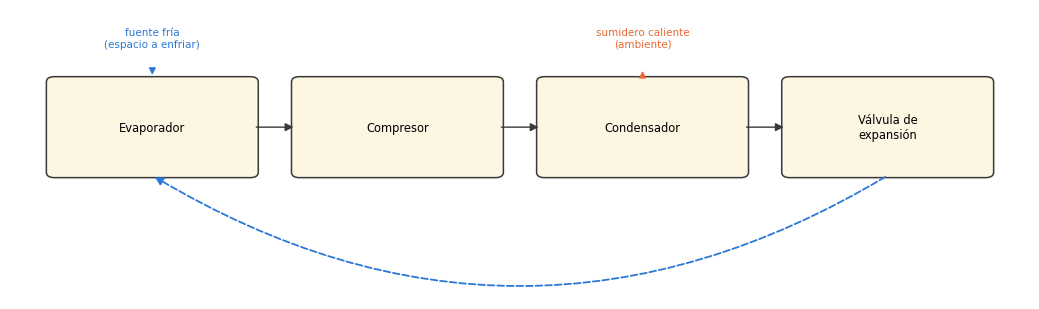

In [ ]:
dibujar_ciclo_refrigeracion("compresion")

El ciclo de refrigeración por compresión de vapor es el ciclo más comúnmente utilizado en la mayoría de las aplicaciones de refrigeración. Consiste en cuatro componentes principales: el compresor, el condensador, la válvula de expansión y el evaporador.

### Proceso del ciclo:
1. **Compresión:** El refrigerante en estado de vapor a baja presión es comprimido por el compresor, aumentando su temperatura y presión.
2. **Condensación:** El vapor de refrigerante a alta presión pasa por el condensador, donde libera calor y se condensa a líquido.
3. **Expansión:** El líquido refrigerante pasa por la válvula de expansión, donde su presión y temperatura disminuyen drásticamente.
4. **Evaporación:** El refrigerante a baja presión y temperatura absorbe calor del espacio a refrigerar en el evaporador y se evapora, volviendo al compresor para comenzar el ciclo nuevamente.

### 4.1. Ecuación de Balance de Energía

La energía total en el sistema se conserva, por lo que el calor absorbido en el evaporador más el trabajo del compresor es igual al calor liberado en el condensador:

$$ Q_{in} + W = Q_{out} $$

### 4.2. Coeficiente de Rendimiento (COP)

El COP es una medida de la eficiencia de un ciclo de refrigeración y se define como la relación entre el calor absorbido en el evaporador y el trabajo realizado por el compresor:

$$ COP = \frac{Q_{evap}}{W_{comp}} $$

Donde:
- $Q_{evap}$ es la cantidad de calor absorbido en el evaporador.
- $W_{comp}$ es el trabajo realizado por el compresor.

### 4.3. Ecuación de la Eficiencia del Compresor ($\eta_c$)

La eficiencia del compresor se define como la relación entre el trabajo real y el trabajo ideal necesarios para comprimir el refrigerante:

$$ \eta_c = \frac{W_{real}}{W_{ideal}} $$

## 5. Ciclo de Refrigeración por Absorción

El ciclo de refrigeración por absorción es una alternativa al ciclo de compresión de vapor, especialmente en aplicaciones donde la electricidad es costosa o no está disponible. En lugar de un compresor, utiliza un absorbedor y un generador para circular el refrigerante.

El coeficiente de rendimiento (COP) para un refrigerador por absorción se define de manera similar al ciclo de compresión de vapor, pero el trabajo del compresor es reemplazado por el calor suministrado al generador.

$$ COP = \frac{Q_{evap}}{Q_{gen}} $$

Donde:
- $Q_{evap}$ es la cantidad de calor absorbido en el evaporador.
- $Q_{gen}$ es la cantidad de calor suministrado al generador.

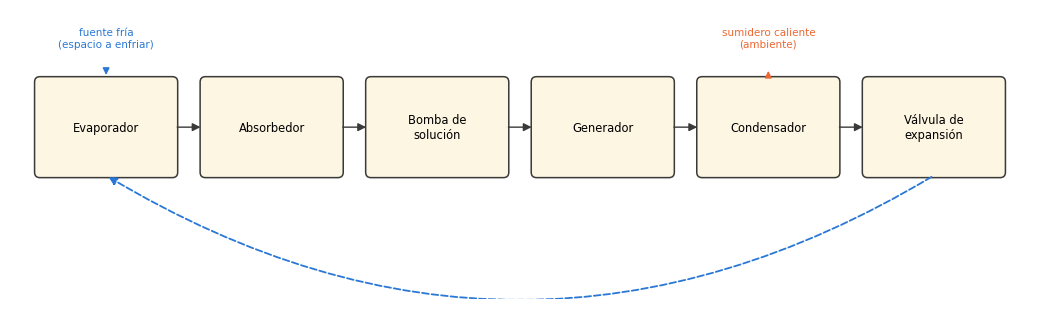

In [ ]:
dibujar_ciclo_refrigeracion("absorcion")

A diferencia de los ciclos de refrigeración por compresión, donde un solo fluido (refrigerante) experimenta cambios de fase, los ciclos de refrigeración por absorción involucran dos fluidos principales: un refrigerante y un absorbente. Estos dos fluidos interactúan entre sí, lo que resulta en fenómenos de absorción y desorción.

### 5.1. Química del Cambio de Fase

En el ciclo de absorción, el refrigerante se disuelve en el absorbente en el absorbedor, formando una solución diluida. Esta solución luego se lleva al generador, donde se aplica calor para separar el refrigerante del absorbente.

- **Absorción:** Durante este proceso, el refrigerante en forma de vapor es absorbido por el absorbente líquido. A nivel molecular, las moléculas de refrigerante se disuelven en el absorbente debido a las interacciones intermoleculares favorables entre el refrigerante y el absorbente. Esta absorción es un proceso exotérmico, lo que significa que se libera calor.

- **Desorción:** En el generador, se aplica calor a la solución diluida, lo que provoca que el refrigerante se separe del absorbente y se evapore. A nivel molecular, el calor suministrado proporciona la energía necesaria para superar las interacciones intermoleculares entre el refrigerante y el absorbente, permitiendo que el refrigerante se evapore. Este proceso es endotérmico, lo que significa que requiere calor.

### 5.2. Termodinámica del Cambio de Fase en Absorción

Desde una perspectiva termodinámica, el ciclo de absorción es más complejo que el ciclo de compresión debido a la interacción entre el refrigerante y el absorbente.

- **Entalpía de Absorción:** Es la cantidad de calor liberado o absorbido durante el proceso de absorción a presión constante. Es una propiedad importante para determinar la cantidad de calor que debe ser eliminado en el absorbedor.

- **Entalpía de Desorción:** Es la cantidad de calor requerido para separar el refrigerante del absorbente a presión constante en el generador.

Estas entalpías son específicas para cada par refrigerante-absorbente y son esenciales para el diseño y operación de sistemas de refrigeración por absorción.

## 6. Ciclos de refrigeración reales vs ideales

Mientras que el ciclo de Rankine describe un modelo idealizado de un ciclo de refrigeración, en la práctica, existen varias diferencias entre un ciclo real y uno ideal. Estas diferencias se deben principalmente a las pérdidas inherentes en los componentes reales y a las no idealidades en el comportamiento del refrigerante.

Algunas de las principales diferencias son:

- **Pérdidas en el compresor:** En un compresor real, no toda la energía suministrada se utiliza para comprimir el refrigerante. Parte de esta energía se pierde debido a la fricción y otras ineficiencias.
- **Subenfriamiento y sobrecalentamiento:** En ciclos reales, el refrigerante puede no condensarse o evaporarse completamente en el condensador o evaporador, respectivamente. Esto puede llevar a subenfriamiento o sobrecalentamiento, lo que afecta la eficiencia del ciclo.
- **Pérdidas de presión:** En los componentes reales, especialmente en los intercambiadores de calor y las tuberías, existen pérdidas de presión que no se consideran en el modelo idealizado.

A pesar de estas diferencias, el ciclo de Rankine proporciona una base útil para el análisis y diseño de sistemas de refrigeración. Sin embargo, es esencial tener en cuenta estas no idealidades al trabajar con sistemas reales.

El widget siguiente extiende el Widget 1 con las tres no idealidades que la prosa anterior describe cualitativamente: **sobrecalentamiento** en la succión (SH, antes del compresor), **subenfriamiento** en la salida del condensador (SC), y **eficiencia isentrópica del compresor** $\eta_c<1$. Compara el ciclo ideal (Widget 1) contra el real sobre el mismo diagrama P-h.

In [ ]:
# WIDGET 2 -- ciclo real vs. ideal: sobrecalentamiento, subenfriamiento, eta_c
def ciclo_real_vs_ideal(T_evap_C=-10.0, T_cond_C=45.0, SH_C=5.0, SC_C=3.0, eta_c=0.75, fluido="R134a"):
    Te, Tc = T_evap_C+273.15, T_cond_C+273.15
    Pe = PropsSI("P","T",Te,"Q",1,fluido); Pc = PropsSI("P","T",Tc,"Q",1,fluido)

    # ideal (SH=SC=0, eta_c=1)
    h1i = PropsSI("H","P",Pe,"Q",1,fluido); s1i = PropsSI("S","P",Pe,"Q",1,fluido)
    h2i = PropsSI("H","P",Pc,"S",s1i,fluido)
    h3i = PropsSI("H","P",Pc,"Q",0,fluido)
    h4i = h3i
    COP_i = (h1i-h4i)/(h2i-h1i)

    # real
    T1 = Te+SH_C
    h1 = PropsSI("H","P",Pe,"T",T1,fluido) if SH_C > 0 else h1i
    s1 = PropsSI("S","P",Pe,"T",T1,fluido) if SH_C > 0 else s1i
    h2s = PropsSI("H","P",Pc,"S",s1,fluido)
    w_real = (h2s-h1)/eta_c
    h2 = h1+w_real
    T3 = Tc-SC_C
    h3 = PropsSI("H","P",Pc,"T",T3,fluido) if SC_C > 0 else h3i
    h4 = h3
    COP_r = (h1-h4)/w_real

    fig, ax = plt.subplots(figsize=(7.5, 6))
    plot_dome_Ph(fluido, ax)
    hi = np.array([h1i,h2i,h3i,h4i,h1i])/1e3; Pi = np.array([Pe,Pc,Pc,Pe,Pe])/1e3
    hr = np.array([h1,h2,h3,h4,h1])/1e3; Pr = np.array([Pe,Pc,Pc,Pe,Pe])/1e3
    ax.plot(hi, Pi, "--", color=COL["evaporador"], lw=1.8, label=f"ideal (COP={COP_i:.2f})")
    ax.plot(hr, Pr, "-o", color=COL["compresor"], lw=2.2, ms=5, label=f"real (COP={COP_r:.2f})")
    ax.legend(fontsize=9.5, loc="lower right")
    ax.set_title(f"SH={SH_C:.0f}°C   SC={SC_C:.0f}°C   $\\eta_c$={eta_c:.2f}   "
                 f"caída de COP: {100*(COP_i-COP_r)/COP_i:.1f} %")
    plt.tight_layout(); plt.show()

interact(ciclo_real_vs_ideal,
         T_evap_C=FloatSlider(-10.0, min=-30.0, max=10.0, step=1.0, description="T evap. [°C]"),
         T_cond_C=FloatSlider(45.0, min=25.0, max=60.0, step=1.0, description="T cond. [°C]"),
         SH_C=FloatSlider(5.0, min=0.0, max=20.0, step=1.0, description="sobrecalent. [°C]"),
         SC_C=FloatSlider(3.0, min=0.0, max=15.0, step=1.0, description="subenfriam. [°C]"),
         eta_c=FloatSlider(0.75, min=0.5, max=1.0, step=0.05, description="η compresor"),
         fluido=Dropdown(options=["R134a", "R410A", "Ammonia", "R290"], value="R134a", description="refrigerante"));

interactive(children=(FloatSlider(value=-10.0, description='T evap. [°C]', max=10.0, min=-30.0, step=1.0), Flo…

## 7. Compresor

El compresor es el corazón del ciclo de refrigeración y tiene la función principal de comprimir el refrigerante, lo que aumenta su temperatura y presión. Al hacerlo, el refrigerante se convierte en un gas a alta presión y temperatura. Esta compresión es esencial para mover el refrigerante a través del sistema y permitir la transferencia de calor.

![image](https://www.mundohvacr.com/wp-content/uploads/2010/02/83-refrigeracion3.jpg)

### 7.1 Tipos de Compresores

Existen varios tipos de compresores utilizados en sistemas de refrigeración:

1. **Compresores de Pistón:** Son los más comunes y utilizan un pistón que se mueve hacia adelante y hacia atrás dentro de un cilindro para comprimir el refrigerante.

![image](https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcTUiAFSDq1JgyyvajCPGnkGmj4lSpyo51KmePSV3ve12DD4YbxGDwxEJdAECEUsVsDX7ZI&usqp=CAU)

2. **Compresores de Tornillo:** Utilizan dos tornillos helicoidales que, al girar, comprimen el refrigerante entre ellos.

![image](https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcQHTEg78t64UUHYeqGfbJNG1psr6NsA-IMfothtLIk5cDdYl4gdP5ndBwE-qO7gNBWK2TQ&usqp=CAU)

3. **Compresores Centrífugos:** Utilizan un rotor que gira a alta velocidad para comprimir el refrigerante mediante la acción centrífuga.

![image](https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcTxnN-Zmcxxqccqd10OWy1qRqbQ4FH2CAE-yjlfhmyHWzudg3mvvqaIQeazbXwtZAQBDt8&usqp=CAU)

4. **Compresores Scroll:** Utilizan dos espirales interconectadas que comprimen el refrigerante al moverse una contra la otra.

![image](https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcT04bJl4TWISL28rw89zS20vU5BqdxR507tNloyA2i6zreIIXtHiXc0hxF6u1D0VdfOAiw&usqp=CAU)

![image](https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcSV9R5xMEPVcHOpSrBI9gz_tyM129zpy2dTxBiwXp5z23sDcGMK4-EkYX0B67hQ9IOiRiY&usqp=CAU)

Cada tipo de compresor tiene sus propias ventajas y desventajas, y la elección de uno sobre otro depende de la aplicación específica y de las necesidades del sistema de refrigeración.

Desde una perspectiva termodinámica, el compresor realiza trabajo sobre el refrigerante para aumentar su energía interna y, por lo tanto, su temperatura y presión. La relación entre la presión y la temperatura durante la compresión es descrita por la ecuación de estado del refrigerante específico utilizado.

![image](https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcRu3waw7iPotzjeF4VPzIyt_VaUJIg4tk9VaQ&usqp=CAU)

La eficiencia del compresor se puede describir mediante la relación de compresión, que es la relación entre la presión de descarga y la presión de succión. Matemáticamente, se expresa como:

$$ \text{Relación de Compresión} = \frac{P_{descarga}}{P_{succión}} $$

Donde:

- $P_{descarga}$ es la presión del refrigerante a la salida del compresor.
- $P_{succión}$ es la presión del refrigerante a la entrada del compresor.

Es esencial que el compresor opere dentro de un rango de presiones adecuado para evitar daños y garantizar una operación eficiente del sistema de refrigeración.

La relación de compresión $P_{descarga}/P_{succión}$ es exactamente $P_c/P_e$ del Widget 1 — con los valores por defecto (R134a, -10°C/45°C) es $P_c/P_e\approx 1160/201\approx 5.8$. Cuanto mayor la relación de compresión, mayor el trabajo del compresor y menor el COP (verificable directamente moviendo los sliders $T_{evap}$/$T_{cond}$ del Widget 1 en direcciones opuestas).

## 8. Condensador

El condensador es un componente esencial en el ciclo de refrigeración, donde el refrigerante libera calor al ambiente y cambia de estado gaseoso a líquido. Durante este proceso, el refrigerante pasa por un cambio de fase, lo que implica una transferencia de calor latente.

### 8.1. Balance de Masa y Energía

Para un condensador operando en estado estacionario, el balance de masa se puede expresar como:

$$ \dot{m}_{entrada} = \dot{m}_{salida} $$

Donde $\dot{m}$ es la tasa de flujo másico del refrigerante.

El balance de energía, considerando la transferencia de calor y el trabajo realizado, se puede expresar como:

$$ Q_{condensador} = \dot{m} (h_{entrada} - h_{salida}) $$

Donde:

- $Q_{condensador}$ es la tasa de transferencia de calor en el condensador.
- $h_{entrada}$ y $h_{salida}$ son las entalpías del refrigerante a la entrada y salida del condensador, respectivamente.

> **Referencia cruzada.** El desarrollo completo de un condensador real (carcasa-tubos, correlaciones de Nu/Pr/Re para ambos lados, condensación en película de Nusselt, pérdidas al ambiente, modelo transitorio) ya se construyó en la **Lección 14** (`notebooks/17_Lección_Modelación_Intercambiador.ipynb`), con el interruptor `cambio_fase` que generaliza condensador/evaporador y el hallazgo de por qué garantizan cambio de fase (regla de las fases a presión constante). Esta lección se enfoca en el **ciclo completo**; para el detalle del intercambiador en sí, ver esa lección.

### 8.2. Transferencia de Calor y Cambio de Fase

La transferencia de calor en el condensador ocurre principalmente debido al cambio de fase del refrigerante de gas a líquido. Durante este proceso, el refrigerante libera calor latente de condensación. La eficiencia de la transferencia de calor se ve afectada por varios factores, incluidos los números adimensionales de transferencia de calor.

El **número de Nusselt (Nu)** es un número adimensional que relaciona la transferencia de calor convectivo en una superficie con la transferencia de calor conductiva a través del fluido. Se define como:

$$ Nu = \frac{hL}{k} $$

Donde:

- $h$ es el coeficiente de transferencia de calor convectivo.
- $L$ es la longitud característica.
- $k$ es la conductividad térmica del fluido.

El **número de Prandtl (Pr)** es otro número adimensional que relaciona la viscosidad del fluido con su capacidad para conducir calor. Se define como:

$$ Pr = \frac{\mu c_p}{k} $$

Donde:

- $\mu$ es la viscosidad dinámica del fluido.
- $c_p$ es el calor específico a presión constante.

Además, el **número de Reynolds (Re)**, que relaciona las fuerzas inerciales con las fuerzas viscosas en un fluido, también es crucial. Se define como:

$$ Re = \frac{\rho vL}{\mu} $$

Donde:

- $\rho$ es la densidad del fluido.
- $v$ es la velocidad del fluido.
- $L$ es la longitud característica.
- $\mu$ es la viscosidad dinámica del fluido.

Estos números adimensionales, junto con otros parámetros, juegan un papel crucial en la determinación de la eficiencia de la transferencia de calor en el evaporador y en la predicción del tipo de flujo (laminar o turbulento) en el dispositivo.

## 9. Válvula de Expansión

La válvula de expansión es un componente crítico en el ciclo de refrigeración que regula el flujo de refrigerante entre el condensador y el evaporador. Su función principal es reducir la presión del refrigerante, lo que resulta en una disminución en su temperatura. Durante este proceso, el refrigerante no realiza trabajo ni intercambia calor con su entorno.

![image](https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcQrxyGRnTdYXsEG7jy_8wryN6XARt06I4KbYNisKEh_XlWBtcQDzhKsIO2tWe1hi9fWn18&usqp=CAU)

![image](https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcSA_8UJrhVkWKmvKY2R71WO9S4OpEdUX4a_UX6ms_ce3F9wbzhJvrybuFjQnJ9o7eIO9WA&usqp=CAU)

![image](https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcQqA_4C91Y7cOxMZMh-p4IweSzzTBnhC1efw0odX07XsrHRT1TqrHtgxgFYkz-egzWUKiU&usqp=CAU)


![image](https://blogquimobasicos.files.wordpress.com/2017/01/foto-2.jpg?w=307&h=309)

### 9.1. Balance de Masa y Energía

Para una válvula de expansión en estado estacionario, el balance de masa se puede expresar como:

$$ \dot{m}_{entrada} = \dot{m}_{salida} $$

Dado que no hay trabajo ni transferencia de calor en la válvula, el balance de energía se reduce a:

$$ h_{entrada} = h_{salida} $$

Donde $h$ es la entalpía del refrigerante. Esto indica que la entalpía se conserva a través de la válvula de expansión.

### 9.2. Transferencia de Calor y Cambio de Fase

Aunque la válvula de expansión en sí no está diseñada para intercambiar calor, el proceso de expansión puede resultar en un cambio parcial de fase del refrigerante, especialmente si el refrigerante entra a la válvula en un estado cercano al punto de saturación. Este cambio de fase es isentálpico, lo que significa que no hay cambio en la entropía del refrigerante.

La relación entre la entalpía y la entropía durante este proceso se puede describir mediante las ecuaciones de estado del refrigerante y las tablas termodinámicas correspondientes.

Es importante destacar que, aunque puede haber un cambio de fase en la válvula de expansión, la mayoría de la evaporación del refrigerante ocurre en el evaporador, que es el siguiente componente en el ciclo de refrigeración.

**¿Por qué una válvula y no una turbina?** La §1 del Widget 1 ya mostró la respuesta cuantitativa: un expansor isentrópico (hipotético) recuperaría $w_{exp}=h_3-h_{4s}$ y elevaría el COP entre 12 % y 29 % según el refrigerante (verificado arriba). Entonces, ¿por qué los sistemas reales casi nunca usan un expansor? Tres razones físicas, no solo económicas:

1. **El flujo es bifásico.** A la salida de un expansor que recupera trabajo, el refrigerante ya está en la región de dos fases (como el estado 4 del ciclo) — una turbina diseñada para vapor seco se erosiona y pierde eficiencia rápidamente con gotas de líquido (el mismo problema de humedad de la Lección 13, §3).
2. **El trabajo recuperable es pequeño.** $w_{exp}$ es apenas el 15-25 % de $w_{comp}$ en los casos típicos — mucho menor que la ganancia de eficiencia de, por ejemplo, el recalentamiento en un ciclo Rankine de potencia (Lección 13), donde el trabajo en juego es del mismo orden en ambas etapas de turbina.
3. **El control es más simple con una válvula.** Una válvula de expansión termostática regula el flujo según el sobrecalentamiento a la salida del evaporador con un mecanismo puramente mecánico — un expansor de trabajo requiere un eje, sellos y control adicional, con pocas ganancias para la complejidad que añade a esta escala.

## 10. Evaporador

El evaporador es otro componente crucial en el ciclo de refrigeración. En el evaporador, el refrigerante absorbe calor del espacio o sustancia que se desea enfriar y cambia de estado líquido a gaseoso. Este proceso implica una transferencia de calor latente.

### 10.1. Balance de Masa y Energía

Para un evaporador operando en estado estacionario, el balance de masa se puede expresar como:

$$ \dot{m}_{entrada} = \dot{m}_{salida} $$

El balance de energía, considerando la transferencia de calor y el trabajo realizado, se puede expresar como:

$$ Q_{evaporador} = \dot{m} (h_{salida} - h_{entrada}) $$

Donde:

- $Q_{evaporador}$ es la tasa de transferencia de calor en el evaporador.
- $h_{entrada}$ y $h_{salida}$ son las entalpías del refrigerante a la entrada y salida del evaporador, respectivamente.

### 10.2. Transferencia de Calor y Cambio de Fase

La transferencia de calor en el evaporador ocurre principalmente debido al cambio de fase del refrigerante de líquido a gas. Durante este proceso, el refrigerante absorbe calor latente de evaporación del espacio o sustancia que se desea enfriar.



## 11. Ciclo de Refrigeración por Absorción

A diferencia de los sistemas de refrigeración por compresión mecánica, donde un compresor es utilizado para aumentar la presión del refrigerante, los sistemas de refrigeración por absorción utilizan un proceso de absorción y desorción para lograr el mismo objetivo. Estos sistemas son especialmente útiles en aplicaciones donde la energía térmica (como el calor residual o solar) está disponible.

El ciclo de refrigeración por absorción consta de los siguientes componentes principales:

1. **Absorbedor:** Aquí, el refrigerante evaporado es absorbido por una solución, reduciendo la presión y permitiendo que más refrigerante se evapore y enfríe el espacio deseado.
2. **Generador (o Desorbedor):** La solución rica en refrigerante es calentada, lo que provoca que el refrigerante se desorba y se evapore.
3. **Condensador:** Similar al ciclo de compresión, el refrigerante en estado gaseoso se condensa liberando calor.
4. **Válvula de Expansión:** Reduce la presión del refrigerante líquido antes de entrar al evaporador.
5. **Evaporador:** El refrigerante líquido absorbe calor y se evapora, enfriando el espacio deseado.

Adicionalmente, una bomba de solución se utiliza para transportar la solución rica en refrigerante del absorbedor al generador.



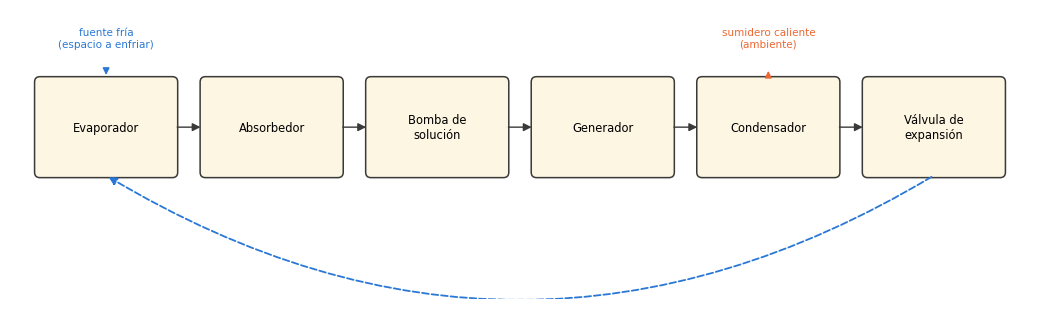

In [ ]:
dibujar_ciclo_refrigeracion("absorcion")

## 12. Absorbedor

El absorbedor juega un papel crucial en el ciclo de refrigeración por absorción. En este componente, el refrigerante vaporizado es absorbido por una solución absorbente, creando una solución rica en refrigerante.

### 12.1. Balance de Masa

Para un absorbedor en estado estacionario, el balance de masa para el refrigerante y la solución absorbente se puede expresar como:

$$ \dot{m}_{ref,entrada} + \dot{m}_{sol,entrada} = \dot{m}_{sol, salida} $$

### 12.2. Balance de Energía

El balance de energía en el absorbedor, considerando la transferencia de calor y el trabajo realizado, se puede expresar como:

$$ Q_{absorbedor} = \dot{m}_{sol} (h_{salida} - h_{entrada}) $$

Donde $Q_{absorbedor}$ es la tasa de transferencia de calor en el absorbedor y $h$ es la entalpía de la solución. El balance de energía, considerando la transferencia de calor y el trabajo realizado, se puede expresar como:

$$ Q_{absorbedor} = \dot{m}_{ref,entrada} h_{ref,entrada} + \dot{m}_{sol,entrada} h_{sol,entrada} - \dot{m}_{sol,salida} h_{sol,salida} $$

Donde $Q_{absorbedor}$ es la tasa de transferencia de calor en el absorbedor y $h$ representa las entalpías correspondientes.

El absorbedor juega un papel crucial en el ciclo de refrigeración por absorción. En este componente, el refrigerante vaporizado se combina con la solución absorbente, resultando en una solución diluida rica en refrigerante.

#### Fases de las Sustancias

Dentro del absorbedor, coexisten dos fases:

1. **Fase de vapor:** Compuesta principalmente por el refrigerante en estado gaseoso.
2. **Fase líquida:** Una solución de refrigerante y absorbente.

El proceso de absorción implica la transferencia de masa del refrigerante desde la fase de vapor a la fase líquida.

### 12.3. Transferencia de Masa y Calor

El proceso de absorción es simultáneamente un fenómeno de transferencia de masa y calor. Mientras el refrigerante se desplaza desde la fase de vapor a la fase líquida, se libera calor debido a la naturaleza exotérmica del proceso.

El coeficiente de transferencia de masa, $k_m$, y el coeficiente de transferencia de calor, $h$, son parámetros esenciales para describir la eficiencia del proceso de absorción. Estos coeficientes dependen de varios factores, incluidos el tipo de refrigerante y absorbente, las propiedades termodinámicas y físicas de la solución, y las condiciones operativas del absorbedor.

El **número de Sherwood (Sh)** es un número adimensional que relaciona la transferencia de masa convectiva en una superficie con la difusión molecular a través del fluido. Se define como:

$$ Sh = \frac{k_m L}{D} $$

Donde:

- $L$ es la longitud característica.
- $D$ es el coeficiente de difusión del refrigerante en la solución absorbente.

Estos números adimensionales, junto con otros parámetros, juegan un papel crucial en la determinación de la eficiencia de la transferencia de masa y calor en el absorbedor.

## 13. Generador (Desorbedor)

El generador, también conocido como desorbedor, es donde la solución rica en refrigerante se calienta, causando que el refrigerante se desorba y se evapore.

### 13.1. Balance de Masa

Para un generador en estado estacionario, el balance de masa para el refrigerante y la solución absorbente se puede expresar como:

$$ \dot{m}_{sol,entrada} = \dot{m}_{ref,salida} + \dot{m}_{sol,salida} $$

### 13.2. Balance de Energía

El balance de energía en el generador, considerando la transferencia de calor y el trabajo realizado, se puede expresar como:

$$ Q_{generador} + W_{bomba} = \dot{m}_{sol} (h_{salida} - h_{entrada}) $$

Donde $Q_{generador}$ es la tasa de transferencia de calor en el generador, $W_{bomba}$ es el trabajo realizado por la bomba de solución y $h$ es la entalpía de la solución. El balance de energía, teniendo en cuenta la transferencia de calor y el trabajo realizado, se puede expresar como:

$$ Q_{generador} = \dot{m}_{sol,entrada} h_{sol,entrada} - (\dot{m}_{ref,salida} h_{ref,salida} + \dot{m}_{sol,salida} h_{sol,salida}) $$

Donde $Q_{generador}$ es la tasa de transferencia de calor en el generador.

Al igual que en el absorbedor, el proceso de desorción en el generador implica tanto la transferencia de masa como de calor. El refrigerante se desplaza desde la fase líquida a la fase de vapor, absorbiendo calor en el proceso.

El coeficiente de transferencia de masa, $k_m$, y el coeficiente de transferencia de calor, $h$, son esenciales para describir la eficiencia del proceso de desorción. Estos coeficientes dependen de varios factores, incluidos el tipo de refrigerante y absorbente, las propiedades termodinámicas y físicas de la solución, y las condiciones operativas del generador.

El **número de Sherwood (Sh)**, previamente definido, es igualmente relevante en el generador para describir la eficiencia de la transferencia de masa. Además, el **número de Reynolds (Re)** y el **número de Prandtl (Pr)**, que relacionan las propiedades del fluido con la transferencia de calor y masa, también son cruciales en el generador.

## 14. Válvula de Expansión (en sistemas de absorción)

Al igual que en los sistemas de compresión, la válvula de expansión en un sistema de absorción reduce la presión del refrigerante antes de que entre al evaporador. Sin embargo, debido a las características únicas del ciclo de absorción, la operación y las consideraciones termodinámicas pueden variar.

### 14.1. Balance de Masa y Energía

Para una válvula de expansión en un sistema de absorción operando en estado estacionario, el balance de masa se puede expresar como:

$$ \dot{m}_{entrada} = \dot{m}_{salida} $$

Dado que no hay trabajo ni transferencia de calor en la válvula, el balance de energía se reduce a:

$$ h_{entrada} = h_{salida} $$

Esto indica que la entalpía se conserva a través de la válvula de expansión, similar a los sistemas de compresión.

## 15. Evaporador (en sistemas de absorción)

El evaporador en un sistema de absorción funciona de manera similar al de un sistema de compresión. Es aquí donde el refrigerante absorbe calor del espacio o sustancia que se desea enfriar y cambia de estado líquido a gaseoso.

### 15.1. Balance de Masa y Energía

Para un evaporador en un sistema de absorción operando en estado estacionario, el balance de masa se puede expresar como:

$$ \dot{m}_{entrada} = \dot{m}_{salida} $$

El balance de energía, considerando la transferencia de calor y el trabajo realizado, se puede expresar como:

$$ Q_{evaporador} = \dot{m} (h_{salida} - h_{entrada}) $$

Donde:

- $Q_{evaporador}$ es la tasa de transferencia de calor en el evaporador.
- $h_{entrada}$ y $h_{salida}$ son las entalpías del refrigerante a la entrada y salida del evaporador, respectivamente.

La transferencia de calor en el evaporador ocurre principalmente debido al cambio de fase del refrigerante de líquido a gas. Durante este proceso, el refrigerante absorbe calor latente de evaporación.

El **número de Nusselt (Nu)**, **número de Prandtl (Pr)** y **número de Reynolds (Re)**, previamente definidos, son igualmente relevantes en el evaporador para describir la eficiencia de la transferencia de calor y la naturaleza del flujo dentro del dispositivo.

## 15.5 Widget — compresión vs. absorción: las dos formas de componer el ciclo

Las dos arquitecturas resuelven el **mismo objetivo** (bombear calor de frío a caliente) con una diferencia esencial: la de compresión consume **trabajo** (electricidad) en el compresor; la de absorción consume **calor** de baja calidad (residual, solar, gas) en el generador, con solo una pequeña bomba de solución. El COP se define distinto en cada caso precisamente por esto — comparar los números directamente solo tiene sentido si se recuerda qué tipo de energía consume cada uno.

> **Declaración de datos.** $COP_{compresión}$ se calcula con el modelo real del Widget 1/2 (CoolProp). No existe en este entorno un modelo de mezcla binaria (LiBr-H₂O o NH₃-H₂O) con el mismo rigor — construir uno excede el alcance de este cuadernillo. $COP_{absorción}$ usa **rangos típicos publicados en la literatura** para enfriadores de absorción de simple efecto LiBr-H₂O (declarado explícitamente como dato de referencia, no calculado con un modelo propio).

In [ ]:
# WIDGET 3 -- compresion vs. absorcion: las dos formas de componer la maquina
def comparar_compresion_absorcion(T_evap_C=-10.0, T_cond_C=45.0, fluido="R134a"):
    Te, Tc = T_evap_C+273.15, T_cond_C+273.15
    Pe = PropsSI("P","T",Te,"Q",1,fluido); Pc = PropsSI("P","T",Tc,"Q",1,fluido)
    h1 = PropsSI("H","P",Pe,"Q",1,fluido); s1 = PropsSI("S","P",Pe,"Q",1,fluido)
    h2 = PropsSI("H","P",Pc,"S",s1,fluido)
    h3 = PropsSI("H","P",Pc,"Q",0,fluido); h4 = h3
    COP_comp = (h1-h4)/(h2-h1)
    COP_abs_rango = (0.65, 0.80)   # LiBr-H2O simple efecto, rango tipico de literatura (declarado)

    fig, ax = plt.subplots(figsize=(7.5, 4.3))
    ax.barh(["Compresión\n(trabajo eléctrico)"], [COP_comp], color=COL["compresor"], height=0.5)
    ax.text(COP_comp, 0, f"  COP={COP_comp:.2f}", va="center", fontsize=10)
    ax.barh(["Absorción\n(calor de baja calidad)"], [COP_abs_rango[1]], color=COL["generador"], alpha=0.35, height=0.5)
    ax.barh(["Absorción\n(calor de baja calidad)"], [COP_abs_rango[0]], color=COL["generador"], height=0.5)
    ax.text(COP_abs_rango[1], 1, f"  COP≈{COP_abs_rango[0]:.2f}-{COP_abs_rango[1]:.2f} (literatura, LiBr-H₂O)",
            va="center", fontsize=9.5)
    ax.set_xlabel("COP"); ax.set_xlim(0, max(COP_comp, COP_abs_rango[1])*1.4)
    ax.set_title("Mismo objetivo, distinta energía de entrada — los números no son directamente comparables")
    plt.tight_layout(); plt.show()
    print(f"Compresión: {fluido}, T_evap={T_evap_C:.0f}°C, T_cond={T_cond_C:.0f}°C -> COP={COP_comp:.2f} "
          f"(por unidad de TRABAJO)")
    print(f"Absorción: LiBr-H2O simple efecto -> COP≈{COP_abs_rango[0]:.2f}-{COP_abs_rango[1]:.2f} "
          f"(por unidad de CALOR al generador, valor de literatura)")

interact(comparar_compresion_absorcion,
         T_evap_C=FloatSlider(-10.0, min=-30.0, max=10.0, step=1.0, description="T evap. [°C]"),
         T_cond_C=FloatSlider(45.0, min=25.0, max=60.0, step=1.0, description="T cond. [°C]"),
         fluido=Dropdown(options=["R134a", "R410A", "Ammonia", "R290"], value="R134a", description="refrigerante"));

interactive(children=(FloatSlider(value=-10.0, description='T evap. [°C]', max=10.0, min=-30.0, step=1.0), Flo…

## 16. Psicrometría

La psicrometría se conecta directamente con la refrigeración:

- El evaporador actúa como **superficie fría** donde el aire cede calor y, si se alcanza el punto de rocío, se produce **condensación de humedad** (deshumidificación).  
- El diseño de sistemas de climatización requiere combinar:
  - **Ciclo de refrigeración del refrigerante**.  
  - **Procesos psicrométricos del aire**.

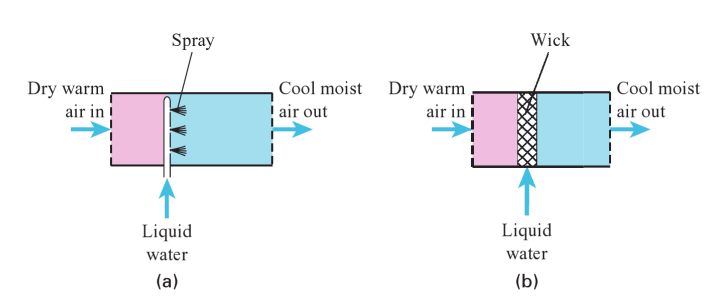

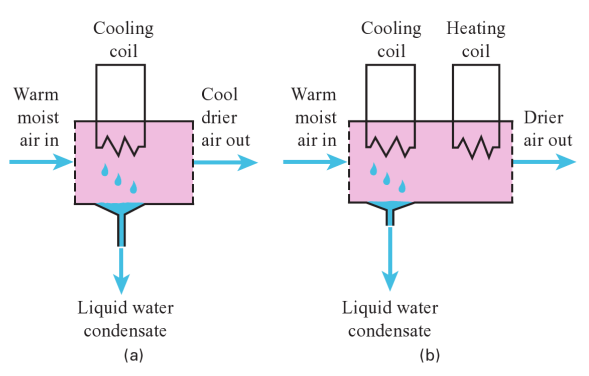

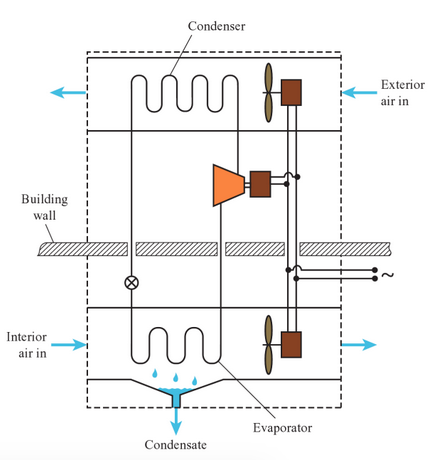

El widget siguiente reemplaza las 8 imágenes sueltas de blog de la celda 43 (temperatura de bulbo seco/húmedo, punto de rocío, humedad relativa/absoluta, entalpía, volumen específico) por **una sola carta psicrométrica real**, calculada con `HAPropsSI` (CoolProp, aire húmedo) — todas esas cantidades se leen directamente de ella, y se traza el proceso de enfriamiento + deshumidificación del evaporador (mismos aparatos de las figuras anteriores).

In [ ]:
# WIDGET 4 -- carta psicrometrica real (CoolProp HAPropsSI) + proceso del evaporador
def carta_psicrometrica(T_aire_C=28.0, RH_pct=60.0, T_salida_evap_C=14.0):
    P = 101325.0
    T1 = T_aire_C+273.15; RH1 = RH_pct/100.0
    w1 = HAPropsSI("W","T",T1,"P",P,"R",RH1)
    Twb1 = HAPropsSI("Twb","T",T1,"P",P,"R",RH1)
    h1 = HAPropsSI("H","T",T1,"P",P,"R",RH1)/1e3
    v1 = HAPropsSI("V","T",T1,"P",P,"R",RH1)

    T2 = T_salida_evap_C+273.15
    RH2 = min(1.0, 0.95)   # aire a la salida del serpentin, cerca de saturacion
    w2 = min(w1, HAPropsSI("W","T",T2,"P",P,"R",RH2))   # no puede ganar humedad en el serpentin

    W_MAX = 30.0   # g/kg -- limite superior visible del eje w
    Tdb = np.linspace(0, 45, 90)+273.15
    fig, ax = plt.subplots(figsize=(9, 6))
    for RH in [0.2, 0.4, 0.6, 0.8, 1.0]:
        w_curve, T_valid = [], []
        for T in Tdb:
            try:
                w = HAPropsSI("W","T",T,"P",P,"R",RH)
            except ValueError:
                continue
            if w*1e3 > W_MAX:   # no graficar/etiquetar mas alla del eje visible
                break
            w_curve.append(w); T_valid.append(T-273.15)
        ax.plot(T_valid, np.array(w_curve)*1e3, color="#999999", lw=1.0 if RH < 1.0 else 1.8)
        ax.text(T_valid[-1], w_curve[-1]*1e3, f" {int(RH*100)}%", fontsize=7.5, color="#777777", va="center")

    ax.plot([T1-273.15], [w1*1e3], "o", ms=10, color=COL["aire"], mec=COL["tinta"], mew=1.3, zorder=5)
    ax.annotate(f"1: entrada\n$T_{{bs}}$={T_aire_C:.0f}°C, $\\phi$={RH_pct:.0f}%", (T1-273.15, w1*1e3),
                textcoords="offset points", xytext=(10,10), fontsize=8.5)
    ax.plot([T2-273.15], [w2*1e3], "o", ms=10, color=COL["evaporador"], mec=COL["tinta"], mew=1.3, zorder=5)
    ax.annotate(f"2: salida evaporador\n$T_{{bs}}$={T_salida_evap_C:.0f}°C", (T2-273.15, w2*1e3),
                textcoords="offset points", xytext=(-90,-25), fontsize=8.5)
    ax.plot([T1-273.15, T2-273.15], [w1*1e3, w2*1e3], "--", color=COL["perdida"], lw=1.8, zorder=4)

    ax.set_xlabel("$T_{bs}$ [°C]"); ax.set_ylabel("$w$ [g agua / kg aire seco]")
    ax.set_xlim(0, 45); ax.set_ylim(0, 30)
    ax.set_title("Carta psicrométrica — enfriamiento + deshumidificación (evaporador como superficie fría)")
    plt.tight_layout(); plt.show()
    print(f"Estado 1: T_bh={Twb1-273.15:.1f}°C   h={h1:.1f} kJ/kg a.s.   v={v1:.3f} m³/kg a.s.   "
          f"w={w1*1e3:.2f} g/kg")
    print(f"Agua condensada en el evaporador: {(w1-w2)*1e3:.2f} g/kg de aire seco "
          f"({'deshumidifica' if w2 < w1 else 'sin deshumidificación (T salida > punto de rocío)'})")

interact(carta_psicrometrica,
         T_aire_C=FloatSlider(28.0, min=10.0, max=40.0, step=1.0, description="T aire [°C]"),
         RH_pct=FloatSlider(60.0, min=20.0, max=95.0, step=5.0, description="HR [%]"),
         T_salida_evap_C=FloatSlider(14.0, min=5.0, max=25.0, step=1.0, description="T salida evap. [°C]"));

interactive(children=(FloatSlider(value=28.0, description='T aire [°C]', max=40.0, min=10.0, step=1.0), FloatS…

### 16.1 Carta psicrométrica

La carta psicrométrica relaciona:

- **Temperatura de bulbo seco** $T_{\text{BS}}$.  
- **Humedad específica o razón de humedad** $w$.  
- **Temperatura de bulbo húmedo** $T_{\text{BH}}$.  
- **Humedad relativa** $\phi$.  
- **Entalpía específica del aire húmedo** $h$.  
- **Volumen específico del aire húmedo** $v$.

Con esta carta se pueden analizar procesos típicos:

- **Enfriamiento y deshumidificación** (coils de expansión directa).  
- **Calentamiento sensible**.  
- **Humidificación** (adiabática / no adiabática).  



## Instrumentación: comparación con el ciclo Rankine de potencia

El ciclo de refrigeración comparte los 4 mismos tipos de instrumento que el ciclo Rankine de potencia (Lección 13: termómetros, manómetros, caudalímetros) — pero con una diferencia conceptual que vale la pena marcar explícitamente: el **Rankine de potencia entrega trabajo neto** (la turbina produce mucho más de lo que la bomba consume, Lección 13 §3), mientras que el **ciclo de refrigeración consume trabajo neto** (solo el compresor; la válvula de expansión no entrega nada — ni siquiera lo que un expansor hipotético podría recuperar, §9). Por eso un medidor de potencia en un ciclo de refrigeración mide **consumo**, no generación.

In [ ]:
# WIDGET 5 -- instrumentacion del ciclo de refrigeracion (mismo patron de NB16/17)
def dibujar_instrumentos_refrig(ax, x, y, tipo, color):
    r = 0.11
    ax.add_patch(Circle((x, y), r, fc="white", ec=color, lw=1.3, zorder=6))
    ax.text(x, y, tipo, ha="center", va="center", fontsize=6.0, zorder=7, fontweight="bold")

def widget_instrumentacion_refrig(modo="compresion"):
    ruta = [("evaporador", "Evaporador"), ("compresor", "Compresor"),
            ("condensador", "Condensador"), ("valvula", "Válvula")] if modo == "compresion" else \
           [("evaporador", "Evaporador"), ("absorbedor", "Absorbedor"), ("bomba_sol", "Bomba sol."),
            ("generador", "Generador"), ("condensador", "Condensador"), ("valvula", "Válvula")]
    n = len(ruta)
    fig, ax = plt.subplots(figsize=(11, 3.4))
    xs = np.linspace(0.9, 0.9+1.55*(n-1), n)
    y = 1.0
    for x, (clave, nombre) in zip(xs, ruta):
        ax.add_patch(FancyBboxPatch((x-0.62, y-0.42), 1.24, 0.84, boxstyle="round,pad=0.05",
                                     fc="#fdf6e3", ec=COL["tinta"], lw=1.1))
        ax.text(x, y, nombre, ha="center", va="center", fontsize=8.0)
    for k in range(n-1):
        ax.add_patch(FancyArrowPatch((xs[k]+0.64, y), (xs[k+1]-0.64, y), arrowstyle="-|>",
                                      mutation_scale=11, color=COL["tinta"]))
        xm = (xs[k]+xs[k+1])/2
        dibujar_instrumentos_refrig(ax, xm, y+0.30, "T\nP", COL["perdida"])
    ax.add_patch(FancyArrowPatch((xs[-1], y-0.45), (xs[0], y-0.45), connectionstyle="arc3,rad=-0.3",
                                  arrowstyle="-|>", mutation_scale=11, color=COL["evaporador"], lw=1.3, ls="--"))
    dibujar_instrumentos_refrig(ax, (xs[0]+xs[-1])/2, y-0.95, "Q", COL["evaporador"])
    ax.text((xs[0]+xs[-1])/2, y-1.4, "caudalímetro de refrigerante", fontsize=7.5, ha="center", color=COL["evaporador"])
    i_comp = [k for k,(c,_) in enumerate(ruta) if c in ("compresor","bomba_sol")]
    for k in i_comp:
        ax.add_patch(FancyArrowPatch((xs[k], y-0.45), (xs[k], y-0.65), arrowstyle="-|>",
                                      mutation_scale=10, color=COL["compresor"]))
        ax.text(xs[k], y-0.95, "W (trabajo\nconsumido)", ha="center", fontsize=6.8, color=COL["compresor"])
    ax.set_xlim(xs[0]-0.9, xs[-1]+0.9); ax.set_ylim(-2.0, y+0.9); ax.axis("off")
    plt.tight_layout(); plt.show()
    print("T = termopar/RTD   P = manómetro   Q = caudalímetro   W = vatímetro/torquímetro")

interact(widget_instrumentacion_refrig, modo=Dropdown(options=["compresion", "absorcion"], description="ciclo"));

interactive(children=(Dropdown(description='ciclo', options=('compresion', 'absorcion'), value='compresion'), …

## 17. Resumen conceptual

- Las máquinas de refrigeración **transportan calor** desde una fuente fría hacia una fuente caliente usando **trabajo o calor** como insumo principal.  
- El **cambio de fase** del refrigerante y sus propiedades termodinámicas ( \(h,s,v\) ) son el núcleo de la operación de los ciclos por **compresión de vapor** y por **absorción**.  
- El **diagrama P–h** es la herramienta estándar para el análisis de estos ciclos.  
- El **COP** es la métrica principal de desempeño, distinta para ciclos de compresión y de absorción.  
- Los **ciclos reales** incluyen pérdidas, subenfriamiento, sobrecalentamiento y caídas de presión, que deben ser considerados en diseño e implementación.  
- En acondicionamiento de aire, la **psicrometría** permite conectar el comportamiento del **aire húmedo** con el ciclo de refrigeración del refrigerante.


| Tipo de ciclo | Energía de entrada | COP típico |
|---|---|---|
| Compresión de vapor (A/C doméstico) | Trabajo eléctrico | 3-4 |
| Compresión de vapor (refrigeración industrial) | Trabajo eléctrico | 2-3 |
| Absorción LiBr-H₂O (simple efecto) | Calor (residual/solar/gas) | 0.65-0.80 |
| Absorción LiBr-H₂O (doble efecto) | Calor (alta T) | 1.0-1.2 |

*(Valores de literatura, declarados como referencia — no calculados con un modelo propio de mezcla binaria en este cuadernillo, ver Widget 3.)*